# Step 3: Visualizing the Olist Project Data
**CSE 578: Data Visualization · Olist E-Commerce Project**

This notebook visualizes the **300 orders prepared in Step 2** (`step2/output/orders.csv`) with nine charts, each answering its own business scenario.
The sample is fixed: no random sampling happens here.

Step 2's `customers.csv` covers only the first 200 of the 300 orders (October 2016 to March 2018).
So that every chart covers the same full period, the location, order value and payment-approval time of **all 300 orders** are looked up in the original Kaggle CSV files (`data/olist/`) by `order_id` and `customer_id`.
That is an exact join, not a sample. A check below confirms the result agrees with Step 2's `customers.csv` for its 200 customers.

| Source file | Used for | Department |
|---|---|---|
| `step2/output/orders.csv` | The 300 orders, status and delivery timestamps | Logistics and Fulfillment |
| `data/olist/olist_customers_dataset.csv` | Customer state and ZIP prefix | Sales and Marketplace Operations |
| `data/olist/olist_order_items_dataset.csv` | Order value (price + freight) | Sales and Marketplace Operations |
| `data/olist/olist_orders_dataset.csv` | Payment approval time | Logistics and Fulfillment |
| `step2/output/customers.csv` | Consistency check only | Sales and Marketplace Operations |

| # | Chart | Scenario (business question) | Department | Library |
|---|---|---|---|---|
| 1 | Histogram | How much is a typical order worth? | Sales | Seaborn |
| 2 | Density plot | How does actual delivery time compare with the time promised at checkout? | Logistics | Seaborn |
| 3 | Box plot | Do customers in different regions wait different lengths of time? | Logistics | Seaborn |
| 4 | Violin plot | Which fulfillment stage takes the most time, and what shape do the stage durations take? | Logistics | Seaborn |
| 5 | Dot plot | How does typical spending differ between states, and do a few big orders distort the average? | Sales | Matplotlib |
| 6 | Strip plot | At what time of day do customers buy, and does it change by weekday? | Sales | Matplotlib |
| 7 | Swarm plot | Has the delivery promise become more or less reliable over time? | Logistics | Seaborn |
| 8 | Bar chart | How has monthly order volume grown? | Sales | Matplotlib |
| 9 | Bar chart, log scale | How common are orders that were not delivered normally? | Logistics | Matplotlib |

Charts 2, 3, 4, 5, 6 and 7 compare several groups or features within one chart.
Every chart is saved as a PNG in `step3/charts/`, and the prepared dataset in `step3/data/step3_dataset.csv`.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "step3" else Path.cwd()
STEP2_DIR = PROJECT_DIR / "step2" / "output"
RAW_DIR = PROJECT_DIR / "data" / "olist"
STEP3_DIR = PROJECT_DIR / "step3"
CHART_DIR = STEP3_DIR / "charts"
DATA_DIR = STEP3_DIR / "data"

REQUIRED_FILES = [
    STEP2_DIR / "orders.csv",
    STEP2_DIR / "customers.csv",
    RAW_DIR / "olist_orders_dataset.csv",
    RAW_DIR / "olist_customers_dataset.csv",
    RAW_DIR / "olist_order_items_dataset.csv",
]
missing = [str(path) for path in REQUIRED_FILES if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Missing input files (run this notebook from the project root or step3/, "
        "after step2/step2.ipynb and the Kaggle download):\n" + "\n".join(missing)
    )

CHART_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Colors checked for color-vision deficiency: blue for a single series, then orange and aqua
# for a second and third series; red only for "late". Text stays in neutral grays.
BLUE = "#2a78d6"
LIGHT_BLUE = "#86b6ef"
DARK_BLUE = "#1c5cab"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
RED = "#d03b3b"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 11,
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "axes.titlecolor": INK_SECONDARY,
    "axes.labelsize": 11,
    "axes.labelcolor": INK_SECONDARY,
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.frameon": False,
    "legend.fontsize": 10,
})
pd.set_option("display.max_colwidth", 90)


def add_titles(fig, ax, title: str, subtitle: str) -> None:
    """Bold headline stating the finding, with a gray subtitle describing what is plotted."""
    fig.suptitle(title, x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
    ax.set_title(subtitle, pad=10)


def save(fig, file_name: str) -> None:
    path = CHART_DIR / file_name
    fig.savefig(path)
    print(f"Saved {path.relative_to(PROJECT_DIR)}")


def clock(hours: float) -> str:
    """Format a time of day in hours (e.g. 14.99) as HH:MM, rounding to the nearest minute."""
    minutes = int(round(hours * 60))
    return f"{minutes // 60:02d}:{minutes % 60:02d}"


def feature_summary(data: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Observed data type, count and range (or categories) of each feature."""
    rows = []
    for column in columns:
        values = data[column].dropna()
        if pd.api.types.is_datetime64_any_dtype(values):
            observed = f"{values.min():%Y-%m-%d} to {values.max():%Y-%m-%d}"
        elif pd.api.types.is_numeric_dtype(values) and not pd.api.types.is_bool_dtype(values):
            observed = f"{values.min():,.2f} to {values.max():,.2f}"
        else:
            categories = values.astype(str).value_counts()
            observed = f"{len(categories)} values: " + ", ".join(categories.index[:8]) + (" …" if len(categories) > 8 else "")
        rows.append({"feature": column, "dtype": str(data[column].dtype), "non-null": len(values),
                     "observed range / values": observed})
    return pd.DataFrame(rows)

## 2. Data preparation and analysis

### 2.1 Load the Step 2 sample and the matching raw records

In [2]:
DATE_COLUMNS = [
    "order_purchase_timestamp",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
# ZIP prefixes are codes, not numbers: read them as text so leading zeros survive (e.g. "05580").
ZIP_AS_TEXT = {"customer_zip_code_prefix": str}

orders = pd.read_csv(STEP2_DIR / "orders.csv", parse_dates=DATE_COLUMNS)
step2_customers = pd.read_csv(STEP2_DIR / "customers.csv", dtype=ZIP_AS_TEXT)

raw_approval = pd.read_csv(RAW_DIR / "olist_orders_dataset.csv", usecols=["order_id", "order_approved_at"],
                           parse_dates=["order_approved_at"])
raw_customers = pd.read_csv(RAW_DIR / "olist_customers_dataset.csv", dtype=ZIP_AS_TEXT)
raw_items = pd.read_csv(RAW_DIR / "olist_order_items_dataset.csv")

# Order value = sum of item price + freight, the same definition used in Step 2.
order_values = (
    raw_items.assign(item_value=raw_items["price"] + raw_items["freight_value"])
    .groupby("order_id")["item_value"].sum().round(2).rename("order_value")
)

print(f"Step 2 orders.csv:    {orders.shape[0]} rows x {orders.shape[1]} columns")
print(f"Step 2 customers.csv: {step2_customers.shape[0]} rows x {step2_customers.shape[1]} columns")
print("\nMissing values in orders.csv:")
print(orders.isna().sum().to_string())

Step 2 orders.csv:    300 rows x 7 columns
Step 2 customers.csv: 200 rows x 6 columns

Missing values in orders.csv:
order_id                         0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_delivered_carrier_date     2
order_delivered_customer_date    5
order_estimated_delivery_date    0


Missing delivery dates belong to the 5 orders that are still shipped or invoiced, or were canceled, so they are expected.
Delivery measures below use only the 295 delivered orders.

### 2.2 Join, clean and derive the analysis features
- **Join:** each of the 300 orders gets its payment-approval time, customer state and ZIP prefix, and order value. The joins are one-to-one, and the code stops if any order is missing a match.
- **Durations** in days, split into the three fulfillment stages:
  - *payment approval*: purchase → payment approved
  - *seller handling*: payment approved → handed to the carrier
  - *carrier transit*: handed to the carrier → delivered
- **Cleaning:** a stage with a negative duration (a timestamp recorded out of order) is a data-entry error, so it is set to missing instead of being averaged in.
- **Normalization:** ZIP prefixes are kept as 5-character text; durations are all in days; each state is mapped to one of Brazil's five regions; the weekday is an ordered category (Monday to Sunday).

In [3]:
STATE_TO_REGION = {
    **dict.fromkeys(["AC", "AP", "AM", "PA", "RO", "RR", "TO"], "North"),
    **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "Northeast"),
    **dict.fromkeys(["DF", "GO", "MT", "MS"], "Central-West"),
    **dict.fromkeys(["ES", "MG", "RJ", "SP"], "Southeast"),
    **dict.fromkeys(["PR", "RS", "SC"], "South"),
}
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
STAGES = {
    "approval_days": "Payment approval\n(purchase to approved)",
    "handling_days": "Seller handling\n(approved to carrier)",
    "transit_days": "Carrier transit\n(carrier to customer)",
}


def days_between(start: pd.Series, end: pd.Series) -> pd.Series:
    return (end - start).dt.total_seconds() / 86_400


data = (
    orders
    .merge(raw_approval, on="order_id", how="left", validate="one_to_one")
    .merge(raw_customers, on="customer_id", how="left", validate="one_to_one")
    .merge(order_values, left_on="order_id", right_index=True, how="left", validate="one_to_one")
)
unmatched = data[["order_approved_at", "customer_state", "order_value"]].isna().sum()
if (unmatched[["customer_state", "order_value"]] > 0).any():
    raise ValueError(f"Some Step 2 orders have no match in the raw files:\n{unmatched}")

purchase = data["order_purchase_timestamp"]
data["customer_region"] = data["customer_state"].map(STATE_TO_REGION)
data["purchase_month"] = purchase.dt.to_period("M").dt.to_timestamp()
data["purchase_quarter"] = purchase.dt.to_period("Q").astype(str)
data["purchase_weekday"] = pd.Categorical(purchase.dt.day_name(), categories=WEEKDAYS, ordered=True)
data["purchase_time_of_day"] = purchase.dt.hour + purchase.dt.minute / 60
data["delivery_days"] = days_between(purchase, data["order_delivered_customer_date"])
data["promised_days"] = days_between(purchase, data["order_estimated_delivery_date"])
data["approval_days"] = days_between(purchase, data["order_approved_at"])
data["handling_days"] = days_between(data["order_approved_at"], data["order_delivered_carrier_date"])
data["transit_days"] = days_between(data["order_delivered_carrier_date"], data["order_delivered_customer_date"])
data["delay_days"] = (data["order_delivered_customer_date"].dt.normalize()
                      - data["order_estimated_delivery_date"]).dt.days.astype("Int64")
data["is_late"] = (data["delay_days"] > 0).astype("boolean")

for column in STAGES:
    negative = data[column] < 0
    print(f"{column:<14} negative durations set to missing: {negative.sum()}")
    data.loc[negative, column] = np.nan

delivered = data[data["delivery_days"].notna()]
print(f"\nAnalysis dataset: {data.shape[0]} orders x {data.shape[1]} columns; delivered: {len(delivered)}")

approval_days  negative durations set to missing: 0
handling_days  negative durations set to missing: 2
transit_days   negative durations set to missing: 0

Analysis dataset: 300 orders x 25 columns; delivered: 295


In [4]:
# Consistency check: the raw lookup must reproduce Step 2's customers.csv exactly for its 200 customers.
check = step2_customers.merge(data[["customer_id", "customer_state", "customer_zip_code_prefix", "order_value"]],
                              on="customer_id", suffixes=("_step2", ""), validate="one_to_one")
zip_matches = check["customer_zip_code_prefix_step2"].astype(int) == check["customer_zip_code_prefix"].astype(int)
if not (len(check) == len(step2_customers)
        and (check["customer_state_step2"] == check["customer_state"]).all()
        and np.allclose(check["order_value_step2"], check["order_value"])
        and zip_matches.all()):
    raise ValueError("Raw lookup does not match step2/output/customers.csv")
print(f"All {len(check)} Step 2 customers match: same state, ZIP prefix and order value.")
print(f"Purchase dates of those 200: {check.merge(data[['customer_id', 'order_purchase_timestamp']])['order_purchase_timestamp'].agg(['min', 'max']).dt.date.tolist()}")
print(f"Purchase dates of all 300:   {data['order_purchase_timestamp'].agg(['min', 'max']).dt.date.tolist()}")

All 200 Step 2 customers match: same state, ZIP prefix and order value.
Purchase dates of those 200: [datetime.date(2016, 10, 6), datetime.date(2018, 3, 27)]
Purchase dates of all 300:   [datetime.date(2016, 10, 6), datetime.date(2018, 8, 29)]


### 2.3 Data dictionary
Type, measurement scale, unit and domain (possible values) of every feature in the prepared dataset. The table after it lists the **observed** range of each feature, computed from the data.

| Feature | Data type | Scale | Unit | Domain (possible values) | Source |
|---|---|---|---|---|---|
| `order_value` | float | ratio | R$ (Brazilian real) | > 0 | order items: price + freight |
| `customer_state` | categorical | nominal | none | 27 Brazilian state codes | customers |
| `customer_region` | categorical | nominal | none | North, Northeast, Central-West, Southeast, South | derived from state |
| `customer_zip_code_prefix` | categorical (code) | nominal | none | 5-digit text, 01000 to 99999 | customers |
| `order_status` | categorical | nominal | none | delivered, shipped, invoiced, canceled, … | orders.csv |
| `purchase_month` | date/time | interval | month | Oct 2016 to Aug 2018 | derived from purchase time |
| `purchase_quarter` | categorical | ordinal | quarter | 2016Q4 to 2018Q3 | derived from purchase time |
| `purchase_weekday` | categorical | ordinal | none | Monday to Sunday | derived from purchase time |
| `purchase_time_of_day` | float | interval (cyclic) | hours | 0.00 to 23.99 (00:00 to 23:59) | derived from purchase time |
| `delivery_days` | float | ratio | days | ≥ 0 | delivered − purchase |
| `promised_days` | float | ratio | days | ≥ 0 | promised date − purchase |
| `approval_days` | float | ratio | days | ≥ 0 | payment approved − purchase |
| `handling_days` | float | ratio | days | ≥ 0 (negatives removed) | handed to carrier − payment approved |
| `transit_days` | float | ratio | days | ≥ 0 | delivered − handed to carrier |
| `delay_days` | integer | interval (0 = promised date) | days | any integer; < 0 early, > 0 late | delivered date − promised date |
| `is_late` | Boolean | nominal | none | True / False | delay_days > 0 |

In [5]:
FEATURES = [
    "order_value", "customer_state", "customer_region", "customer_zip_code_prefix", "order_status",
    "purchase_month", "purchase_quarter", "purchase_weekday", "purchase_time_of_day", "delivery_days",
    "promised_days", "approval_days", "handling_days", "transit_days", "delay_days", "is_late",
]
feature_summary(data, FEATURES)

,feature,dtype,non-null,observed range / values
0,order_value,float64,300,"18.22 to 1,562.57"
1,customer_state,str,300,"20 values: SP, RJ, MG, SC, RS, BA, PR, ES …"
2,customer_region,str,300,"5 values: Southeast, South, Northeast, Central-West, North"
3,customer_zip_code_prefix,str,300,"296 values: 86037, 13175, 22775, 22220, 83540, 05580, 53230, 64049 …"
4,order_status,str,300,"4 values: delivered, shipped, canceled, invoiced"
5,purchase_month,datetime64[us],300,2016-10-01 to 2018-08-01
6,purchase_quarter,str,300,"8 values: 2018Q1, 2018Q2, 2017Q4, 2018Q3, 2017Q3, 2017Q2, 2017Q1, 2016Q4"
7,purchase_weekday,category,300,"7 values: Wednesday, Tuesday, Thursday, Sunday, Friday, Monday, Saturday"
8,purchase_time_of_day,float64,300,0.02 to 23.92
9,delivery_days,float64,295,1.15 to 68.84


In [6]:
data.to_csv(DATA_DIR / "step3_dataset.csv", index=False)
print(f"Saved {(DATA_DIR / 'step3_dataset.csv').relative_to(PROJECT_DIR)}")

Saved step3/data/step3_dataset.csv


---
## Chart 1: Histogram, order value

**Scenario (Sales and Marketplace Operations).** Pricing and promotion decisions depend on how much a typical order is worth.
Are most orders small or large? Is there a long tail of big orders?

**Features**

| Feature | Data type | Scale | Unit | Observed range |
|---|---|---|---|---|
| `order_value` | float | ratio | R$ | R$ 18.22 to R$ 1,562.57 (300 orders) |

**Why a histogram.** `order_value` is one continuous numeric feature. A histogram groups the values into equal-width bins (R$ 25 here) and shows how many orders fall in each bin.
That reveals where most values sit, how spread out they are, whether the distribution is skewed, and any outliers.

**Library.** Seaborn `histplot`, which handles binning in one call; Matplotlib adds the mean and median labels.

Saved step3/charts/01_histogram_order_value.png


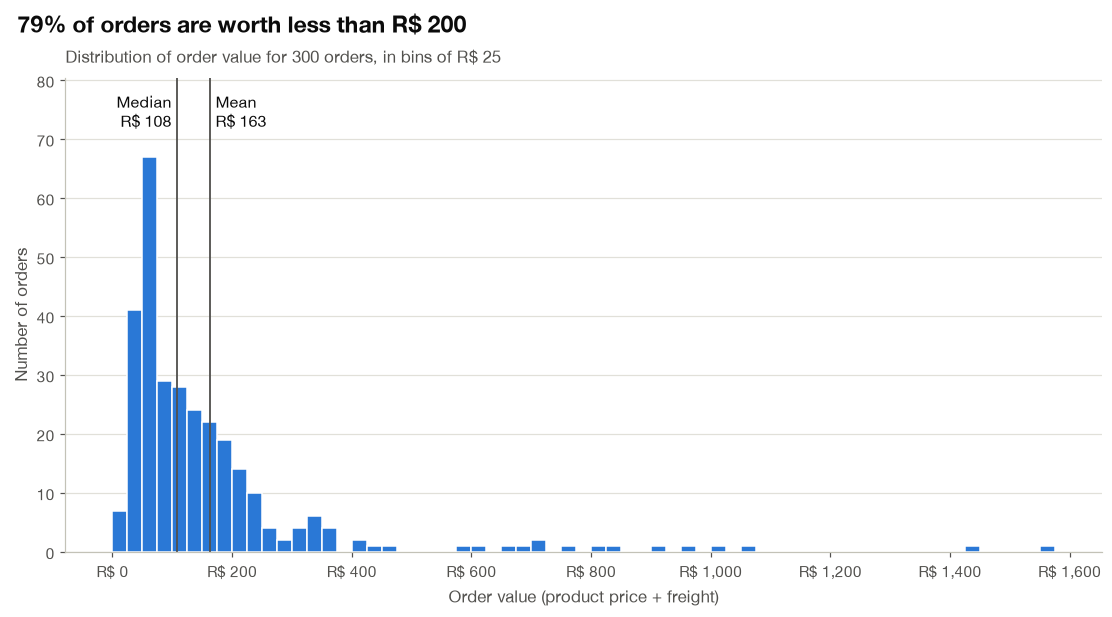

Median R$ 108.06 · mean R$ 162.80 · skewness 3.77 · max R$ 1,562.57
Under R$ 100: 48% · under R$ 200: 79% · over R$ 500: 15 orders
Tallest bin: R$ 50 to R$ 75 (67 orders)


In [7]:
BIN_WIDTH = 25
values = data["order_value"]
median_value, mean_value = values.median(), values.mean()
upper_edge = np.ceil(values.max() / BIN_WIDTH) * BIN_WIDTH  # covers every order, so none are dropped
bin_counts, _ = np.histogram(values, bins=np.arange(0, upper_edge + BIN_WIDTH, BIN_WIDTH))
under_200 = (values < 200).mean()

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
sns.histplot(values, binwidth=BIN_WIDTH, binrange=(0, upper_edge), color=BLUE, alpha=1, edgecolor="white",
             linewidth=1, ax=ax)

top = bin_counts.max() * 1.2
ax.set_ylim(0, top)
for value, label, side in [(median_value, "Median", "right"), (mean_value, "Mean", "left")]:
    ax.axvline(value, color=INK_SECONDARY, linewidth=1.2)
    offset = -upper_edge * 0.006 if side == "right" else upper_edge * 0.006
    ax.text(value + offset, top * 0.97, f"{label}\nR$ {value:,.0f}", ha=side, va="top", fontsize=10.5, color=INK)

ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("R$ {x:,.0f}"))
ax.set_xlabel("Order value (product price + freight)")
ax.set_ylabel("Number of orders")
ax.grid(axis="x", visible=False)
add_titles(fig, ax, f"{under_200:.0%} of orders are worth less than R$ 200",
           f"Distribution of order value for {len(values)} orders, in bins of R$ {BIN_WIDTH}")
save(fig, "01_histogram_order_value.png")
plt.show()

print(f"Median R$ {median_value:.2f} · mean R$ {mean_value:.2f} · skewness {values.skew():.2f} · max R$ {values.max():,.2f}")
print(f"Under R$ 100: {(values < 100).mean():.0%} · under R$ 200: {under_200:.0%} · over R$ 500: {(values > 500).sum()} orders")
print(f"Tallest bin: R$ {bin_counts.argmax() * BIN_WIDTH} to R$ {(bin_counts.argmax() + 1) * BIN_WIDTH} ({bin_counts.max()} orders)")

**Interpretation.**
- The distribution is strongly **right-skewed** (skewness 3.8). The tallest bin is R$ 50 to R$ 75 (67 orders), and 79% of orders are worth less than R$ 200.
- A thin tail of large orders reaches R$ 1,563; 15 orders are above R$ 500.
- The tail pulls the **mean (R$ 163) well above the median (R$ 108)**, so the median describes a "typical" order better.
- For Sales, the core business is low-priced items. Promotions such as free shipping above a threshold would likely work best near R$ 100 to R$ 150, where many orders already are.

---
## Chart 2: Density plot, actual vs promised delivery time

**Scenario (Logistics and Fulfillment).** At checkout Olist shows the customer an estimated delivery date.
Does it promise much more time than it actually needs? A padded promise protects the late-delivery rate but can cost sales, because long estimates discourage buyers.

**Features** (295 delivered orders)

| Feature | Data type | Scale | Unit | Observed range |
|---|---|---|---|---|
| `delivery_days` | float | ratio | days | 1.2 to 68.8 |
| `promised_days` | float | ratio | days | 4.5 to 55.3 |

**Why a density plot.** We compare the shapes of **two continuous distributions** on the same axis.
Overlapping histograms would hide each other's bars, while two smooth density curves (kernel density estimates) stay readable together.
Each curve is a probability density, so its height shows the **share** of orders per day. The two curves are directly comparable, and the horizontal gap between them shows how much extra time is promised.
The curves are smoothed, so a small part of each would fall below 0 days; that impossible region is not drawn (`clip=(0, None)`).
A vertical marker shows each distribution's median.

**Library.** Seaborn `kdeplot`.

*Comparison chart: two features in one plot.*

Saved step3/charts/02_density_delivery_vs_promised.png


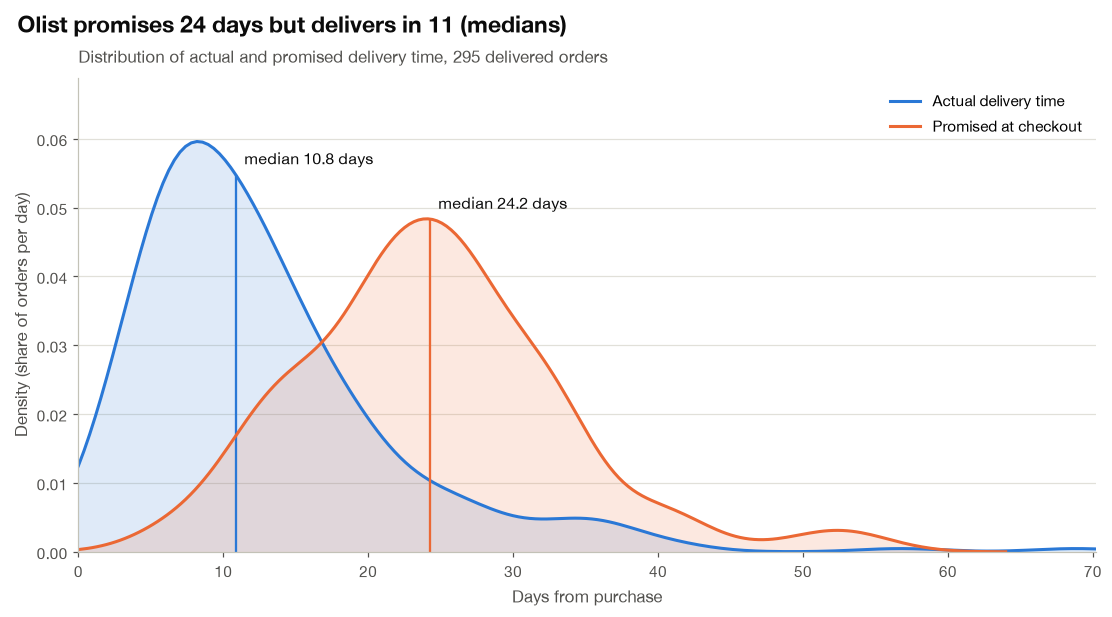

      delivery_days  promised_days
0.25            6.9           18.4
0.75           15.8           29.6
0.90           24.0           34.1
Delivered on or before the promised date: 92.2%


In [8]:
series = [("delivery_days", "Actual delivery time", BLUE), ("promised_days", "Promised at checkout", ORANGE)]
medians = {column: delivered[column].median() for column, _, _ in series}

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
for column, label, color in series:
    sns.kdeplot(delivered[column], ax=ax, color=color, fill=True, alpha=0.15, linewidth=0, clip=(0, None))
    sns.kdeplot(delivered[column], ax=ax, color=color, linewidth=2, clip=(0, None), label=label)
    x_curve, y_curve = ax.lines[-1].get_data()
    height = np.interp(medians[column], x_curve, y_curve)
    ax.vlines(medians[column], 0, height, color=color, linewidth=1.5)
    ax.text(medians[column] + 0.6, height + 0.001, f"median {medians[column]:.1f} days",
            fontsize=10.5, color=INK, va="bottom")

ax.set_xlim(0, delivered[["delivery_days", "promised_days"]].max().max() * 1.02)
ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
ax.set_xlabel("Days from purchase")
ax.set_ylabel("Density (share of orders per day)")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
add_titles(fig, ax, f"Olist promises {medians['promised_days']:.0f} days but delivers in {medians['delivery_days']:.0f} (medians)",
           f"Distribution of actual and promised delivery time, {len(delivered)} delivered orders")
save(fig, "02_density_delivery_vs_promised.png")
plt.show()

quantiles = delivered[["delivery_days", "promised_days"]].quantile([0.25, 0.75, 0.9]).round(1)
print(quantiles)
print(f"Delivered on or before the promised date: {(~delivered['is_late']).mean():.1%}")

**Interpretation.**
- The **actual** curve peaks at about one week and is right-skewed: half of the orders arrive in 7 to 16 days (median 10.8), 90% within 24 days, and a few take over a month.
- The **promised** curve sits about two weeks to the right (median 24.2 days) and is more symmetric; the middle half of promises are between 18 and 30 days.
- The curves overlap only between about 15 and 25 days, and order by order **92% arrive on or before their promised date**.
- For Logistics, the promise is very conservative. Shortening estimates in regions where deliveries are reliably fast could make offers more attractive without hurting on-time performance.

---
## Chart 3: Box plot, delivery time by customer region

**Scenario (Logistics and Fulfillment).** Most sellers are in the Southeast, and Brazil is continental in size.
Do customers in distant regions wait noticeably longer? Which regions need better carrier coverage?

**Features** (295 delivered orders)

| Feature | Data type | Scale | Unit | Observed range / domain |
|---|---|---|---|---|
| `customer_region` | categorical | nominal | none | 5 regions: Southeast (203), South (47), Northeast (28), Central-West (12), North (5) |
| `delivery_days` | float | ratio | days | 1.2 to 68.8 |

**Why a box plot.** We compare the distribution of one numeric feature across **several groups**.
Each box shows the five-number summary: median, quartiles (the middle 50% of orders), whiskers (1.5 × IQR) and individual outliers.
Five groups side by side are easier to compare as boxes than as five overlapping histograms.

**Library.** Seaborn `boxplot`, ordered by median so the ranking reads left to right.

*Comparison chart: five groups.*

Saved step3/charts/03_boxplot_delivery_by_region.png


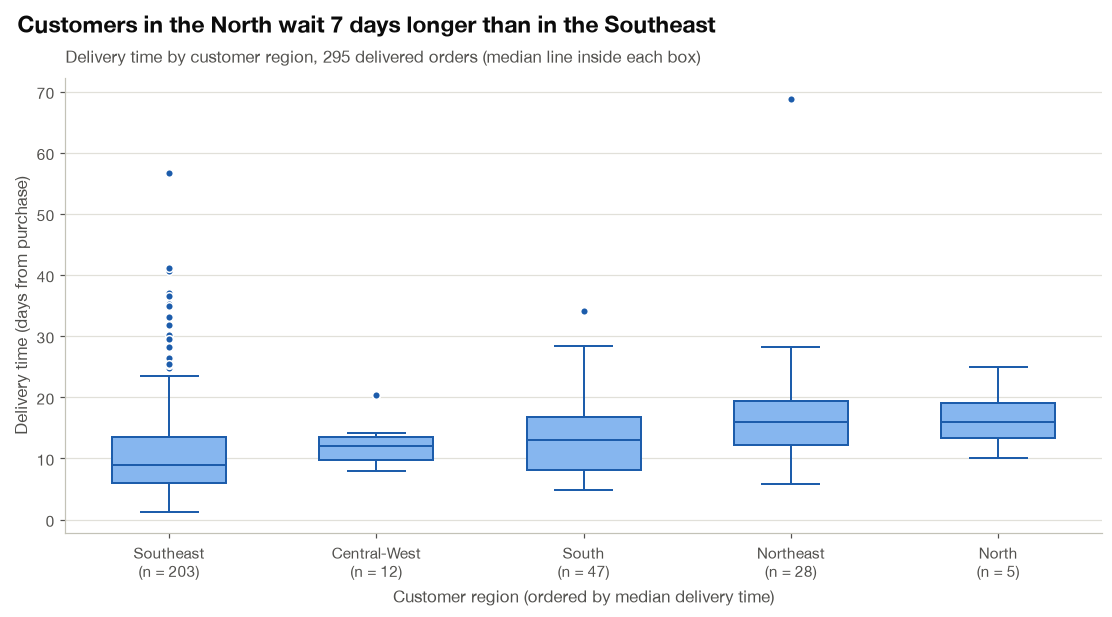

,count,mean,std,min,25%,50%,75%,max
customer_region,,,,,,,,
Southeast,203.0,11.6,9.1,1.2,6.0,8.9,13.5,56.7
Central-West,12.0,12.6,4.2,7.9,9.7,12.1,13.5,20.4
South,47.0,13.7,6.6,4.9,8.1,13.1,16.8,34.2
Northeast,28.0,17.8,11.3,5.9,12.2,15.9,19.3,68.8
North,5.0,16.7,5.7,10.1,13.4,15.9,19.0,25.0


In [9]:
region_stats = delivered.groupby("customer_region")["delivery_days"].describe()
region_order = region_stats["50%"].sort_values().index.tolist()
fastest, slowest = region_order[0], region_order[-1]
gap = region_stats.loc[slowest, "50%"] - region_stats.loc[fastest, "50%"]

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
sns.boxplot(data=delivered, x="customer_region", y="delivery_days", order=region_order,
            color=LIGHT_BLUE, linecolor=DARK_BLUE, linewidth=1.3, width=0.55, saturation=1,
            flierprops=dict(marker="o", markersize=5, markerfacecolor=DARK_BLUE, markeredgecolor="white"), ax=ax)

ax.set_xticks(range(len(region_order)),
              labels=[f"{region}\n(n = {region_stats.loc[region, 'count']:.0f})" for region in region_order])
ax.set_xlabel("Customer region (ordered by median delivery time)")
ax.set_ylabel("Delivery time (days from purchase)")
ax.grid(axis="x", visible=False)
add_titles(fig, ax, f"Customers in the {slowest} wait {gap:.0f} days longer than in the {fastest}",
           f"Delivery time by customer region, {len(delivered)} delivered orders (median line inside each box)")
save(fig, "03_boxplot_delivery_by_region.png")
plt.show()

region_stats.loc[region_order].round(1)

**Interpretation.**
- The **Southeast** is fastest (median 8.9 days), followed by the Central-West (12.1) and the South (13.1). Customers in the **Northeast** and **North** (median about 15.9 days each) wait about **7 days longer** than in the Southeast.
- The Southeast has the most outliers (up to 57 days) because it has by far the most orders. The **Northeast** has the single longest delivery (68.8 days) and the widest spread (standard deviation 11.3 days).
- The North has only 5 orders and the Central-West 12, so their boxes are less certain. The full dataset (see the dashboard) shows the same pattern: Southeast fastest, Northeast and North slowest.
- For Logistics, distance from the sellers in the Southeast drives waiting time. Regional carrier partners or warehouses in the Northeast would give the biggest improvement.

---
## Chart 4: Violin plot, distribution shape of the fulfillment stages

**Scenario (Logistics and Fulfillment).** An order's waiting time has three stages, each controlled by a different party.
**Payment approval** (purchase until the payment is confirmed) depends on the payment method; **seller handling** (approval until the parcel is handed to the carrier) is up to the seller; **carrier transit** (carrier until delivery) is up to the shipping company.
Which stage takes the most time, and is it consistently slow or only occasionally slow?

**Features** (the 293 delivered orders with all three stages recorded; 2 orders whose carrier date is earlier than their approval date are excluded)

| Feature | Data type | Scale | Unit | Observed range |
|---|---|---|---|---|
| `approval_days` | float | ratio | days | 0.00 to 3.83 |
| `handling_days` | float | ratio | days | 0.04 to 35.55 |
| `transit_days` | float | ratio | days | 0.68 to 66.05 |

**Why a violin plot.** A violin is a box plot combined with a mirrored density curve, so it shows the **shape** of each distribution as well as its summary:
where values pile up, how long the tail is, and whether there is more than one peak. Inside each violin, the **dashed line is the median** and the **dotted lines are the quartiles** (25th and 75th percentiles).
Using the same orders for all three stages makes them directly comparable.

**Library.** Seaborn `violinplot` with `inner="quart"`; `cut=0` keeps each violin within the observed range.

*Comparison chart: three features in one plot.*

Saved step3/charts/04_violin_fulfillment_stages.png


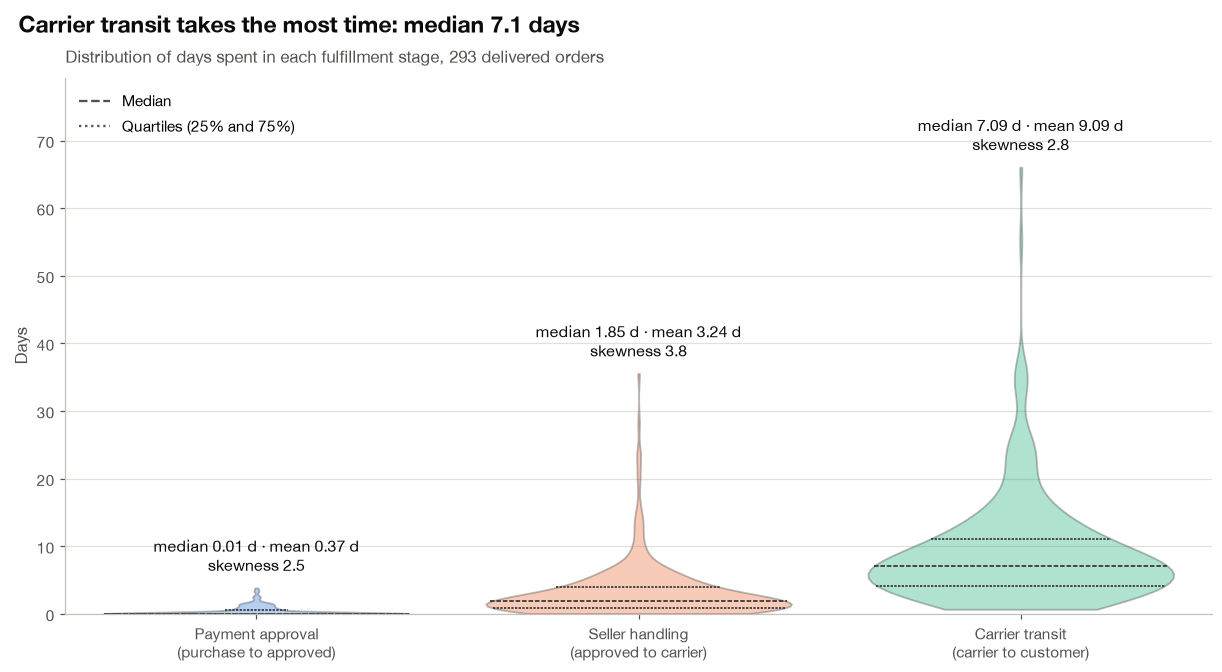

      approval_days  handling_days  transit_days
0.25           0.01           0.88          4.19
0.75           0.53           3.92         11.13
0.90           1.37           6.40         17.89
Orders over 10 days per stage: {'approval_days': 0, 'handling_days': 16, 'transit_days': 88}
Payment approved within 1 hour: 67% · after more than 1 day: 15%


,median,mean,skew,kurt
Payment approval,0.01,0.37,2.49,6.72
Seller handling,1.85,3.24,3.78,19.16
Carrier transit,7.09,9.09,2.77,12.04


In [10]:
complete = delivered.dropna(subset=list(STAGES))
stages = (
    complete.melt(value_vars=list(STAGES), var_name="stage", value_name="days")
    .assign(stage=lambda frame: frame["stage"].map(STAGES))
)
shape = complete[list(STAGES)].agg(["median", "mean", "skew", "kurt"]).T
longest = shape["median"].idxmax()

fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
sns.violinplot(data=stages, x="stage", y="days", hue="stage", order=list(STAGES.values()),
               palette=[BLUE, ORANGE, AQUA], legend=False, inner="quart", cut=0, width=0.8,
               linewidth=1.2, saturation=1, ax=ax)
for violin in ax.collections:
    violin.set_alpha(0.35)

for position, (column, stats) in enumerate(shape.iterrows()):
    ax.text(position, complete[column].max() + 2,
            f"median {stats['median']:.2f} d · mean {stats['mean']:.2f} d\nskewness {stats['skew']:.1f}",
            ha="center", va="bottom", fontsize=10.5, color=INK)

ax.set_ylim(0, complete[list(STAGES)].max().max() * 1.2)
ax.set_xlabel("")
ax.set_ylabel("Days")
ax.grid(axis="x", visible=False)
ax.legend(handles=[Line2D([0], [0], color=INK_SECONDARY, linestyle="--", label="Median"),
                   Line2D([0], [0], color=INK_SECONDARY, linestyle=":", label="Quartiles (25% and 75%)")],
          loc="upper left")
add_titles(fig, ax, f"{STAGES[longest].split(chr(10))[0]} takes the most time: median {shape.loc[longest, 'median']:.1f} days",
           f"Distribution of days spent in each fulfillment stage, {len(complete)} delivered orders")
save(fig, "04_violin_fulfillment_stages.png")
plt.show()

print(complete[list(STAGES)].quantile([0.25, 0.75, 0.9]).round(2))
print(f"Orders over 10 days per stage: {(complete[list(STAGES)] > 10).sum().to_dict()}")
print(f"Payment approved within 1 hour: {(complete['approval_days'] <= 1 / 24).mean():.0%} · after more than 1 day: {(complete['approval_days'] > 1).mean():.0%}")
shape.rename(index=lambda column: STAGES[column].split("\n")[0]).round(2)

**Interpretation, including distribution shape.**
- **Payment approval** is almost instant: the median is 0.01 days (about 15 minutes) and 75% of orders are approved within half a day. About 15% wait more than a day (up to 3.8 days), most likely orders paid by *boleto* (a bank slip that is only confirmed once the customer pays it).
- **Seller handling** is short and tightly packed: median 1.9 days, half of orders between 0.9 and 3.9 days. Its long, thin tail up to 36 days comes from a few slow sellers (16 orders over 10 days).
- **Carrier transit** takes the most time (median 7.1 days) and is the most spread out (middle half between 4.2 and 11.1 days); **88 orders spend more than 10 days in transit**.
- **Shape:** all three distributions are **unimodal** (one peak) and **right-skewed** (skewness 2.5, 3.8 and 2.8). Values bunch near zero with long tails of rare delays, so the **mean is always larger than the median**. The high kurtosis (6.7, 19.2 and 12.0) confirms that the tails are heavy: extreme delays are more common than a normal distribution would predict.
- For Logistics, the carrier stage is the bottleneck. Faster or more consistent carrier service would shorten waits more than pushing sellers, although the few very slow sellers should still be followed up.

---
## Chart 5: Dot plot, typical vs average order value by state

**Scenario (Sales and Marketplace Operations).** Sales wants to know whether customers in some states spend more, so that regional campaigns can be targeted.
The average alone can mislead when a few very large orders occur, so we compare the **median** (typical order) with the **mean** (average) in each state.

**Features** (the 13 states with at least 3 orders; 290 of the 300 orders)

| Feature | Data type | Scale | Unit | Observed range / domain |
|---|---|---|---|---|
| `customer_state` | categorical | nominal | none | 20 states in the sample; 13 with 3+ orders |
| `order_value` (median and mean per state) | float | ratio | R$ | medians R$ 51 to R$ 191; means R$ 76 to R$ 383 |

**Why a dot plot (Cleveland dot plot).** We compare **summary amounts across many categories**.
A dot marks each value's position, so the axis does not need to start at zero the way bars do, and two statistics per state (median and mean) fit on one line without clutter.
The line joining them shows how far large orders pull the mean away from the typical value. Sorting by median makes the ranking easy to read.

**Library.** Matplotlib (`scatter` + `hlines`): a custom layout with two markers per row is simpler to build directly than in Seaborn.

*Comparison chart: 13 states × 2 statistics.*

Saved step3/charts/05_dotplot_order_value_by_state.png


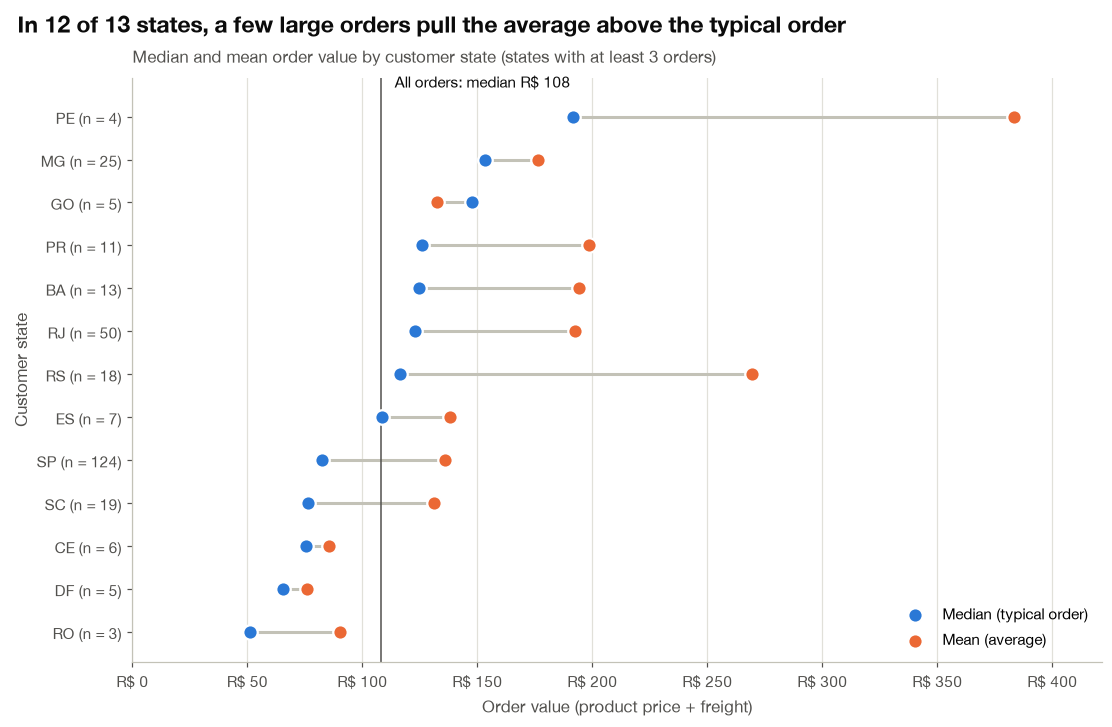

,median,mean,orders
customer_state,,,
RO,51.14,90.06,3
DF,65.35,75.85,5
CE,75.64,85.52,6
SC,76.18,130.94,19
SP,82.62,135.72,124
ES,108.33,138.00,7
RS,116.32,269.35,18
RJ,122.70,192.30,50
BA,124.41,194.11,13


In [11]:
MIN_ORDERS = 3
by_state = (
    data.groupby("customer_state")["order_value"]
    .agg(median="median", mean="mean", orders="count")
    .query("orders >= @MIN_ORDERS")
    .sort_values("median")
)
rows = np.arange(len(by_state))
mean_above_median = (by_state["mean"] > by_state["median"]).sum()

fig, ax = plt.subplots(figsize=(10, 6.5), layout="constrained")
ax.hlines(rows, by_state[["median", "mean"]].min(axis=1), by_state[["median", "mean"]].max(axis=1),
          color="#c3c2b7", linewidth=2, zorder=1)
ax.scatter(by_state["median"], rows, s=90, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3,
           label="Median (typical order)")
ax.scatter(by_state["mean"], rows, s=90, color=ORANGE, edgecolor="white", linewidth=1.5, zorder=3,
           label="Mean (average)")

overall_median = data["order_value"].median()
ax.axvline(overall_median, color=INK_SECONDARY, linewidth=1)
ax.text(overall_median + 6, len(rows) - 0.4, f"All orders: median R$ {overall_median:,.0f}",
        fontsize=10, color=INK, va="bottom")

ax.set_yticks(rows, labels=[f"{state} (n = {n})" for state, n in by_state["orders"].items()])
ax.set_ylim(-0.7, len(rows) - 0.1)
ax.set_xlim(0, by_state["mean"].max() * 1.1)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("R$ {x:,.0f}"))
ax.set_xlabel("Order value (product price + freight)")
ax.set_ylabel("Customer state")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
add_titles(fig, ax, f"In {mean_above_median} of {len(by_state)} states, a few large orders pull the average above the typical order",
           f"Median and mean order value by customer state (states with at least {MIN_ORDERS} orders)")
save(fig, "05_dotplot_order_value_by_state.png")
plt.show()

by_state.round(2)

**Interpretation.**
- **Typical spending** (median) ranges from R$ 51 in Rondônia (RO) to R$ 191 in Pernambuco (PE). The two largest markets, São Paulo (SP, R$ 83, 124 orders) and Santa Catarina (SC, R$ 76), are below the overall median of R$ 108. Minas Gerais (MG, R$ 153, 25 orders) is the largest market with clearly higher typical spending.
- In **12 of the 13 states the mean is above the median**, the same right skew seen in Chart 1. Only Goiás (GO) is the other way round. The gap is largest in **Rio Grande do Sul (RS: mean R$ 269 vs median R$ 116)** and **PE (R$ 383 vs R$ 191)**, where one or two very large orders dominate.
- States with few orders (RO: 3, PE: 4, DF and GO: 5) are unstable, so their positions could change with more data.
- For Sales, ranking states by the mean would wrongly single out RS and PE as high-spending markets. The median shows that MG customers consistently buy more expensive items, which makes them a good target for higher-priced categories.

---
## Chart 6: Strip plot, purchase time of day by weekday

**Scenario (Sales and Marketplace Operations).** When should campaigns, flash sales and customer-support staffing be scheduled?
We look at the exact time of day each order was placed, separately for every weekday.

**Features** (all 300 orders)

| Feature | Data type | Scale | Unit | Observed range / domain |
|---|---|---|---|---|
| `purchase_weekday` | categorical | ordinal (cyclic) | none | Monday to Sunday; 32 to 58 orders per day |
| `purchase_time_of_day` | float | interval (cyclic) | hours | 0.02 to 23.92 (00:01 to 23:55) |

**Why a strip plot.** With about 30 to 60 orders per weekday, we can show **every individual order** as a dot instead of a summary.
A strip plot places the points along the value axis for each category and spreads them a little sideways so they don't overlap. Here the sideways offsets follow a fixed, evenly spaced pattern instead of random jitter, so the chart is identical on every run. The offsets carry no meaning, and the times on the vertical axis stay exact.
It shows both the concentration and the empty times (gaps) that an average would hide. A short black line marks each day's median.

**Library.** Matplotlib `scatter`. Seaborn's `stripplot` only offers random jitter, while placing the points with Matplotlib keeps their positions fixed.

*Comparison chart: seven weekdays.*

Saved step3/charts/06_stripplot_purchase_time_by_weekday.png


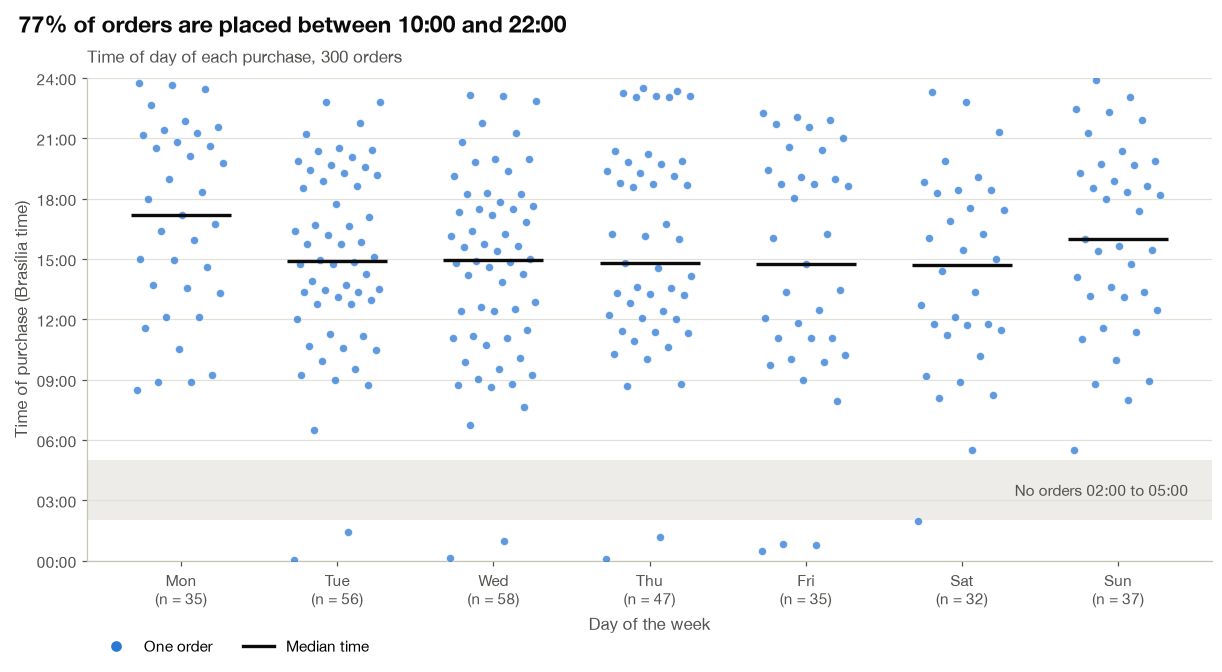

Orders between 10:00 and 22:00: 77% · before 08:00: 5%
Median purchase time by weekday:
purchase_weekday
Monday       17:11
Tuesday      14:54
Wednesday    14:58
Thursday     14:49
Friday       14:44
Saturday     14:42
Sunday       15:59


In [12]:
weekday_counts = data["purchase_weekday"].value_counts()
weekday_medians = data.groupby("purchase_weekday", observed=True)["purchase_time_of_day"].median()
time_of_day = data["purchase_time_of_day"]
daytime_share = ((time_of_day >= 10) & (time_of_day < 22)).mean()

# Longest run of whole hours with no orders, computed from the data.
orders_per_hour = time_of_day.astype(int).value_counts().reindex(range(24), fill_value=0)
empty_run, current = [], []
for hour, count in orders_per_hour.items():
    current = current + [hour] if count == 0 else []
    if len(current) > len(empty_run):
        empty_run = current

fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
if empty_run:
    gap_start, gap_end = empty_run[0], empty_run[-1] + 1
    ax.axhspan(gap_start, gap_end, color=GRID, alpha=0.6, linewidth=0)
    ax.text(6.45, (gap_start + gap_end) / 2, f"No orders {gap_start:02d}:00 to {gap_end:02d}:00",
            ha="right", va="center", fontsize=10, color=INK_SECONDARY)
# Fixed sideways spread: within each day, orders sorted by time get offsets from the golden-ratio
# sequence, which fills the strip evenly without any random numbers.
GOLDEN_RATIO_STEP = (np.sqrt(5) - 1) / 2
strip = data[["purchase_weekday", "purchase_time_of_day"]].sort_values("purchase_time_of_day")
rank_in_day = strip.groupby("purchase_weekday", observed=True).cumcount()
strip_x = strip["purchase_weekday"].cat.codes + ((rank_in_day * GOLDEN_RATIO_STEP) % 1 - 0.5) * 0.56
ax.scatter(strip_x, strip["purchase_time_of_day"], s=28, color=BLUE, alpha=0.75, edgecolor="white",
           linewidth=0.5, zorder=3)
for position, day in enumerate(WEEKDAYS):
    ax.hlines(weekday_medians[day], position - 0.32, position + 0.32, color=INK, linewidth=2.2, zorder=4)

ax.set_ylim(0, 24)
ax.set_yticks(range(0, 25, 3), labels=[f"{hour:02d}:00" for hour in range(0, 25, 3)])
ax.set_xlim(-0.6, 6.6)
ax.set_xticks(range(7), labels=[f"{day[:3]}\n(n = {weekday_counts[day]})" for day in WEEKDAYS])
ax.set_xlabel("Day of the week")
ax.set_ylabel("Time of purchase (Brasília time)")
ax.grid(axis="x", visible=False)
ax.legend(handles=[Line2D([0], [0], marker="o", linestyle="", color=BLUE, label="One order"),
                   Line2D([0], [0], color=INK, linewidth=2.2, label="Median time")],
          loc="upper left", bbox_to_anchor=(0, -0.13), ncols=2)
add_titles(fig, ax, f"{daytime_share:.0%} of orders are placed between 10:00 and 22:00",
           f"Time of day of each purchase, {len(data)} orders")
save(fig, "06_stripplot_purchase_time_by_weekday.png")
plt.show()

print(f"Orders between 10:00 and 22:00: {daytime_share:.0%} · before 08:00: {(time_of_day < 8).mean():.0%}")
print("Median purchase time by weekday:")
print(weekday_medians.apply(clock).to_string())

**Interpretation.**
- On every weekday the dots are dense from about **10:00 to 22:00**, which covers 77% of all orders. Only 5% of orders arrive before 08:00, and there are **none between 02:00 and 05:00**.
- Median purchase times are close to 15:00 on most days. **Monday (17:11)** and **Sunday (15:59)** lean later, suggesting more evening shopping at the start and end of the week.
- **Tuesday and Wednesday** have the most orders in this sample (56 and 58), against 32 to 37 on Friday to Sunday.
- For Sales, campaigns and push notifications work best scheduled for early afternoon and evening, with Tuesday and Wednesday as the strongest days. Customer support needs most staff in the same window, and night shifts can be minimal.

---
## Chart 7: Swarm plot, delivery delay vs promise by quarter

**Scenario (Logistics and Fulfillment, with impact on Customer Experience).** A late delivery is the main reason customers leave bad reviews.
Has the delivery promise become more or less reliable over time, and were there periods when many orders arrived late?

**Features** (295 delivered orders)

| Feature | Data type | Scale | Unit | Observed range / domain |
|---|---|---|---|---|
| `purchase_quarter` | categorical | ordinal | quarter | 2016Q4 to 2018Q3 (8 quarters) |
| `delay_days` | integer | interval (0 = promised date) | days | −45 (45 days early) to +35 (35 days late) |
| `is_late` | Boolean | nominal | none | True (23 orders) / False (272 orders) |

**Why a swarm plot.** Like a strip plot, it shows **every individual order**, but instead of random jitter it places points side by side so that **none overlap** (no randomness at all).
The width of each swarm therefore shows how many orders have that value, like a violin built from real points. With 3 to 65 orders per quarter, every late order stays visible, and color (late in red) highlights them.

**Library.** Seaborn `swarmplot` with `hue` for the late / on-time split.

*Comparison chart: eight quarters × two outcomes.*

Saved step3/charts/07_swarmplot_delay_by_quarter.png


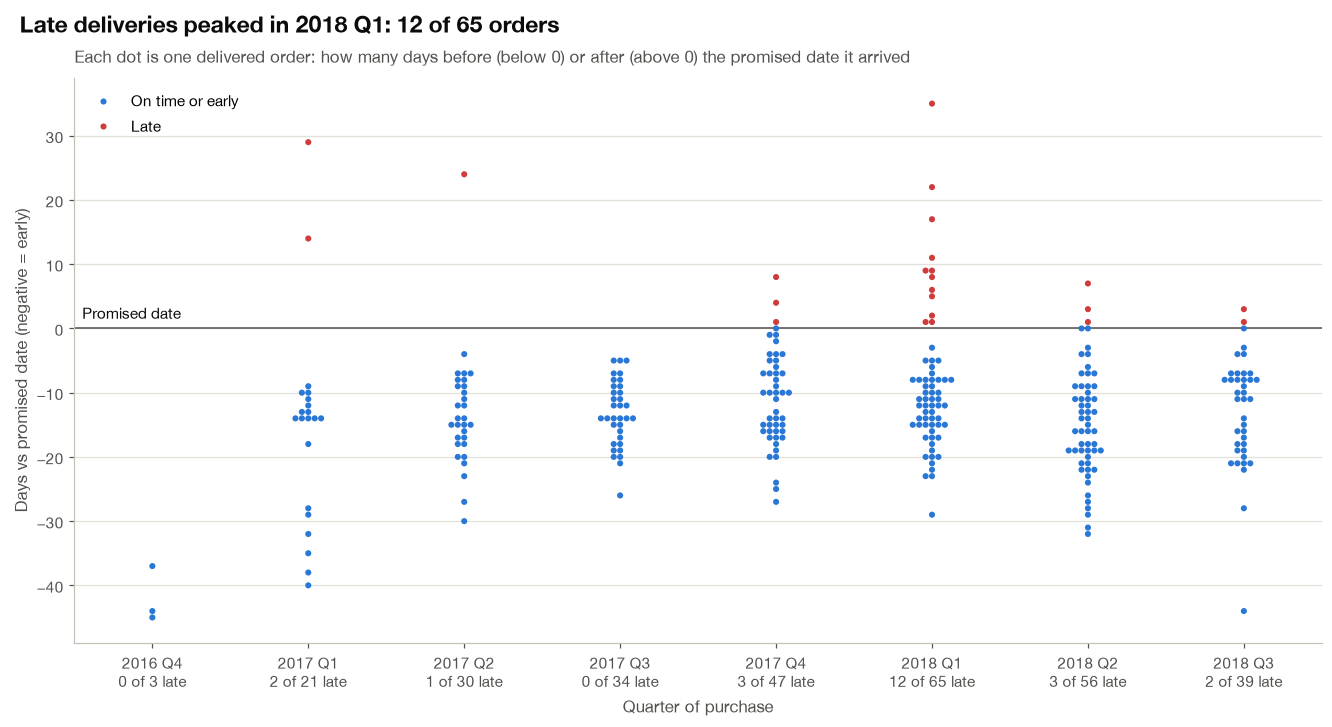

,late_orders,delivered_orders,late_rate,median_delay_days
purchase_quarter,,,,
2016Q4,0,3,0.0,-44.0
2017Q1,2,21,0.095,-14.0
2017Q2,1,30,0.033,-14.5
2017Q3,0,34,0.0,-14.0
2017Q4,3,47,0.064,-10.0
2018Q1,12,65,0.185,-11.0
2018Q2,3,56,0.054,-14.5
2018Q3,2,39,0.051,-11.0


In [13]:
swarm_data = delivered.assign(
    outcome=delivered["is_late"].map({True: "Late", False: "On time or early"}),
    delay_days=delivered["delay_days"].astype(float),
)
quarters = sorted(swarm_data["purchase_quarter"].unique())
late_by_quarter = swarm_data.groupby("purchase_quarter")["is_late"].agg(late_orders="sum", delivered_orders="count")
late_by_quarter["late_rate"] = late_by_quarter["late_orders"] / late_by_quarter["delivered_orders"]
worst = late_by_quarter["late_rate"].idxmax()

fig, ax = plt.subplots(figsize=(12, 6.5), layout="constrained")
ax.axhline(0, color=INK_SECONDARY, linewidth=1, zorder=1)
ax.text(-0.45, 1, "Promised date", ha="left", va="bottom", fontsize=10, color=INK)
sns.swarmplot(data=swarm_data, x="purchase_quarter", y="delay_days", order=quarters,
              hue="outcome", hue_order=["On time or early", "Late"], palette={"On time or early": BLUE, "Late": RED},
              size=4, ax=ax)

ax.set_xticks(range(len(quarters)), labels=[
    f"{quarter[:4]} {quarter[4:]}\n{late_by_quarter.loc[quarter, 'late_orders']} of {late_by_quarter.loc[quarter, 'delivered_orders']} late"
    for quarter in quarters
])
ax.set_xlabel("Quarter of purchase")
ax.set_ylabel("Days vs promised date (negative = early)")
ax.grid(axis="x", visible=False)
ax.legend(title="", loc="upper left")
add_titles(fig, ax,
           f"Late deliveries peaked in {worst[:4]} {worst[4:]}: {late_by_quarter.loc[worst, 'late_orders']} of "
           f"{late_by_quarter.loc[worst, 'delivered_orders']} orders",
           "Each dot is one delivered order: how many days before (below 0) or after (above 0) the promised date it arrived")
save(fig, "07_swarmplot_delay_by_quarter.png")
plt.show()

late_by_quarter.assign(median_delay_days=swarm_data.groupby("purchase_quarter")["delay_days"].median()).round(3)

**Interpretation.**
- In most quarters almost every dot sits **well below zero**: orders typically arrive 10 to 15 days **before** the promised date (median between −10 and −15 days; −44 in the small 2016 Q4 group).
- **2018 Q1 stands out**: 12 of its 65 orders (18%) were late, by up to 35 days. In every other quarter 0 to 3 orders were late (at most 10%). This matches the full dataset in the dashboard, where the late rate peaked at 19% in March 2018, a period of near-record order volume after Black Friday and the holidays.
- 2017 Q3 had no late orders at all, and by 2018 Q2 and Q3 the late rate was back to about 5%, so the problem was temporary.
- For Logistics and Customer Experience, capacity planning before seasonal peaks matters. During high-volume periods the promise should be extended, or carriers given extra capacity, to protect review scores.

---
## Chart 8: Bar chart, monthly order volume

**Scenario (Sales and Marketplace Operations).** How fast is the marketplace growing, and are there seasonal spikes that Sales and Logistics must prepare for?

**Features** (all 300 orders)

| Feature | Data type | Scale | Unit | Observed range |
|---|---|---|---|---|
| `purchase_month` | date/time | interval | month | October 2016 to August 2018 (23 months, including 2 with no orders) |
| orders per month (count of `order_id`) | integer | ratio | orders | 0 to 25 |

**Why a bar chart.** Each bar is a **count** for one month, and bar length directly encodes quantity from a zero baseline, which makes it easy to compare months and spot growth and spikes.
Bars, rather than a line, emphasize that each month is a separate total and keep months with zero orders visible.

**Library.** Matplotlib `bar` with a date axis, which spaces months correctly and keeps the empty months.

*Note: this is a 300-order sample of about 99,000 orders, so the counts are small, but the shape matches the full dataset.*

Saved step3/charts/08_bar_monthly_orders.png


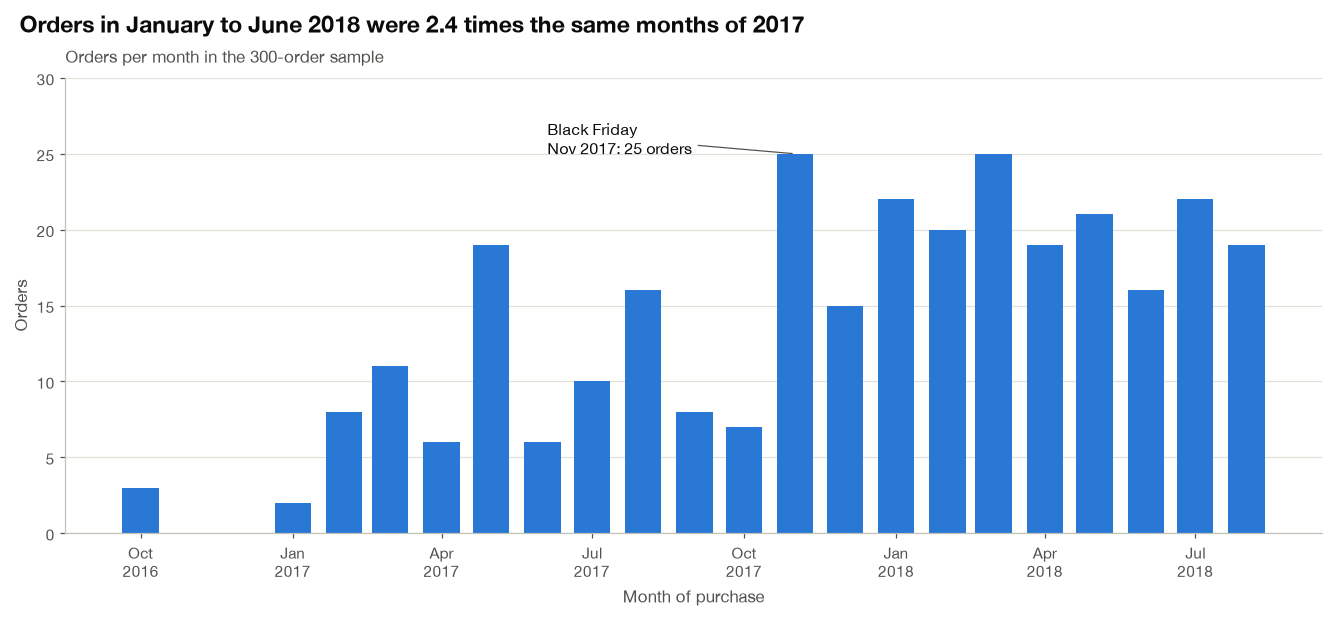

Jan–Jun 2017: 52 orders · Jan–Jun 2018: 123 orders
Oct 2016     3
Nov 2016     0
Dec 2016     0
Jan 2017     2
Feb 2017     8
Mar 2017    11
Apr 2017     6
May 2017    19
Jun 2017     6
Jul 2017    10
Aug 2017    16
Sep 2017     8
Oct 2017     7
Nov 2017    25
Dec 2017    15
Jan 2018    22
Feb 2018    20
Mar 2018    25
Apr 2018    19
May 2018    21
Jun 2018    16
Jul 2018    22
Aug 2018    19


In [14]:
months = pd.date_range(data["purchase_month"].min(), data["purchase_month"].max(), freq="MS")
monthly = data.groupby("purchase_month")["order_id"].count().reindex(months, fill_value=0)
first_half_2017 = monthly["2017-01":"2017-06"].sum()
first_half_2018 = monthly["2018-01":"2018-06"].sum()

fig, ax = plt.subplots(figsize=(12, 5.5), layout="constrained")
ax.bar(monthly.index, monthly.values, width=22, color=BLUE)

black_friday = pd.Timestamp("2017-11-01")
ax.annotate(f"Black Friday\nNov 2017: {monthly[black_friday]} orders", xy=(black_friday, monthly[black_friday]),
            xytext=(black_friday - pd.Timedelta(days=150), monthly[black_friday] + 1),
            fontsize=10.5, color=INK, va="center",
            arrowprops=dict(arrowstyle="-", color=INK_SECONDARY, linewidth=0.8))

ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_ylim(0, monthly.max() * 1.2)
ax.set_xlabel("Month of purchase")
ax.set_ylabel("Orders")
ax.grid(axis="x", visible=False)
add_titles(fig, ax, f"Orders in January to June 2018 were {first_half_2018 / first_half_2017:.1f} times the same months of 2017",
           f"Orders per month in the {len(data)}-order sample")
save(fig, "08_bar_monthly_orders.png")
plt.show()

print(f"Jan–Jun 2017: {first_half_2017} orders · Jan–Jun 2018: {first_half_2018} orders")
print(monthly.rename(lambda month: f"{month:%b %Y}").to_string())

**Interpretation.**
- Order volume **rose through 2017**, from 2 orders in January to between 6 and 19 a month by mid-year, and **stayed at 16 to 25 orders a month throughout 2018**.
- January to June 2018 had **123 orders vs 52** in the same months of 2017, **2.4 times** as many.
- **November 2017 (Black Friday)** is the highest month of 2017 with 25 orders, a sharp jump from 7 in October. Volume stayed high afterwards, with March 2018 also at 25.
- The sample has no orders in November and December 2016, the platform's very early period.
- For Sales, the marketplace was scaling fast, and Black Friday is the key seasonal event. Combined with Chart 7, the post-Black-Friday surge is also when delivery reliability dropped, so Sales and Logistics should plan peaks together.

---
## Chart 9: Bar chart with a logarithmic scale, order status

**Scenario (Logistics and Fulfillment, operations monitoring).** Operations must track orders that did *not* complete normally (still shipped, only invoiced, or canceled), because each one is a potential complaint or refund.
How many are there compared with delivered orders?

**Features** (all 300 orders)

| Feature | Data type | Scale | Unit | Observed range / domain |
|---|---|---|---|---|
| `order_status` | categorical | nominal | none | delivered, shipped, canceled, invoiced (also possible in the full data: processing, unavailable, created, approved) |
| orders per status (count) | integer | ratio | orders | 1 to 295 |

**Why a bar chart with a log scale.** Counts are compared by bar height, but here they span more than **two orders of magnitude** (1 to 295).
On a normal linear axis (left panel) the exception bars are 1/150 the height of the delivered bar and practically invisible.
A **logarithmic axis** (right panel) spaces values by **ratio** instead of difference: 1 → 10 → 100 → 1,000 are equal steps. Small and large counts become readable in the same chart.
This is the same as plotting log₁₀(count): delivered = log₁₀(295) ≈ 2.47, shipped = log₁₀(2) ≈ 0.30, invoiced = log₁₀(1) = 0.

**How it changes interpretation.** On the log axis, bar *length* is no longer proportional to the count, and the bottom of the axis is arbitrary (set at 0.5 here so a count of 1 still shows a bar).
Read each bar's top against the gridlines; the vertical distance between two bars shows their **ratio**, not their difference.

**Library.** Matplotlib, with `set_yscale("log")` and two panels side by side to contrast linear and log scales.

Saved step3/charts/09_logbar_order_status.png


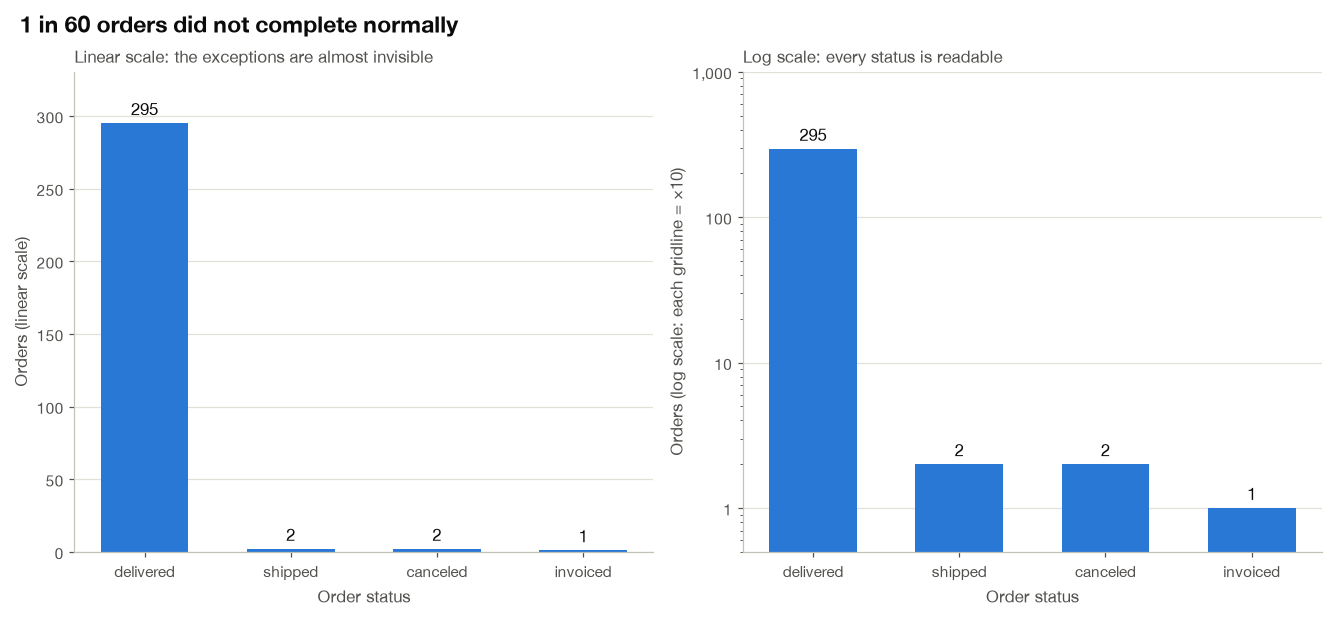

,orders,share,log10_orders
order_status,,,
delivered,295,0.9833,2.47
shipped,2,0.0067,0.30
canceled,2,0.0067,0.30
invoiced,1,0.0033,0.00


In [15]:
status_counts = data["order_status"].value_counts()
exception_share = 1 - status_counts.get("delivered", 0) / status_counts.sum()

fig, (ax_linear, ax_log) = plt.subplots(1, 2, figsize=(12, 5.5), layout="constrained")
for ax in (ax_linear, ax_log):
    bars = ax.bar(status_counts.index, status_counts.values, color=BLUE, width=0.6)
    ax.bar_label(bars, labels=[f"{count:,}" for count in status_counts.values], padding=3, fontsize=11, color=INK)
    ax.set_xlabel("Order status")
    ax.grid(axis="x", visible=False)

ax_linear.set_ylim(0, status_counts.max() * 1.12)
ax_linear.set_ylabel("Orders (linear scale)")
ax_linear.set_title("Linear scale: the exceptions are almost invisible")

ax_log.set_yscale("log")
ax_log.set_ylim(0.5, 10 ** np.ceil(np.log10(status_counts.max() * 1.5)))
ax_log.yaxis.set_major_locator(mticker.LogLocator(base=10))
ax_log.yaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax_log.yaxis.set_minor_formatter(mticker.NullFormatter())
ax_log.set_ylabel("Orders (log scale: each gridline = ×10)")
ax_log.set_title("Log scale: every status is readable")

fig.suptitle(f"1 in {round(1 / exception_share)} orders did not complete normally",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
save(fig, "09_logbar_order_status.png")
plt.show()

status_counts.to_frame("orders").assign(share=lambda frame: (frame["orders"] / frame["orders"].sum()).round(4),
                                        log10_orders=lambda frame: np.log10(frame["orders"]).round(2))

**Interpretation.**
- **295 of 300 orders (98.3%) were delivered.** The 5 exceptions are 2 still *shipped* (in transit with the carrier), 2 *canceled* and 1 only *invoiced*, about **1 in 60 orders**.
- On the **linear** scale those 5 orders barely register, and a reader could conclude there are no problems at all. The **log** scale makes them visible and comparable: *shipped* and *canceled* are equal, *invoiced* is half of them, and *delivered* is about 150 times larger (more than two gridlines of ×10).
- Because the log scale compresses large values, the chart must not be read as "delivered is only a little taller": the gap of about 2.2 decades means a factor of about 150.
- For Operations, the exception rate is low but not zero, and in the full dataset it is higher: about 3,000 of 99,441 orders (3%) were not delivered. Each needs follow-up, which is why tracking them on a log-scale chart alongside delivered orders is useful.

---
## Summary

| # | Chart | Scenario | Key finding |
|---|---|---|---|
| 1 | Histogram | Value of an order | Right-skewed; median R$ 108, 79% of orders under R$ 200 |
| 2 | Density | Actual vs promised delivery | Delivered in ~11 days vs ~24 promised; 92% on time |
| 3 | Box plot | Delivery time by region | Northeast and North wait ~7 days longer than the Southeast |
| 4 | Violin | Fulfillment stage shape | Carrier transit (median 7.1 d) takes the most time; all stages right-skewed with heavy tails |
| 5 | Dot plot | Spending by state | MG customers spend the most per order among large markets; means in RS and PE are inflated by a few large orders |
| 6 | Strip plot | Purchase time by weekday | 77% of orders between 10:00 and 22:00; none 02:00 to 05:00 |
| 7 | Swarm plot | Delivery reliability over time | 18% late in 2018 Q1, at most 10% in other quarters |
| 8 | Bar chart | Monthly order volume | 2.4x growth (H1 2018 vs H1 2017); Black Friday spike |
| 9 | Log bar chart | Order status exceptions | 98.3% delivered; the log scale reveals the 1-in-60 exceptions |

**Main thread across the charts:** delivery speed depends on geography (3) and on the carrier stage (4). Reliability collapsed after the Black Friday volume peak (7, 8), even though Olist's promises are very conservative overall (2).

In [16]:
sorted(path.name for path in CHART_DIR.glob("*.png"))

['01_histogram_order_value.png',
 '02_density_delivery_vs_promised.png',
 '03_boxplot_delivery_by_region.png',
 '04_violin_fulfillment_stages.png',
 '05_dotplot_order_value_by_state.png',
 '06_stripplot_purchase_time_by_weekday.png',
 '07_swarmplot_delay_by_quarter.png',
 '08_bar_monthly_orders.png',
 '09_logbar_order_status.png']